Importing assets.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Colab Notebooks")
ASSETS = PROJECT / "capstone-project-assets"

assert ASSETS.exists(), f"Cannot find {ASSETS}"
print(sorted(path.name for path in ASSETS.iterdir() if path.is_dir()))

Mounted at /content/drive
['boots', 'box', 'coin', 'exit', 'floor', 'gem', 'ghost', 'human', 'key', 'lava', 'locked', 'opened', 'shield', 'wall']


In [ ]:
LABELS = (
    "floor",
    "wall",
    "lava",
    "exit",
    "locked",
    "opened",
    "box",
    "agent",   # asset folder is named "human"
    "gem",
    "coin",
    "key",
    "boots",
    "ghost",
    "shield",
)

ASSET_NAME = {
    "agent": "human",
    **{label: label for label in LABELS if label != "agent"},
}

LABEL_TO_INDEX = {label: index for index, label in enumerate(LABELS)}
INDEX_TO_LABEL = dict(enumerate(LABELS))

print(LABEL_TO_INDEX)

{'floor': 0, 'wall': 1, 'lava': 2, 'exit': 3, 'locked': 4, 'opened': 5, 'box': 6, 'agent': 7, 'gem': 8, 'coin': 9, 'key': 10, 'boots': 11, 'ghost': 12, 'shield': 13}


In [ ]:
from collections import Counter

asset_counts = {
    label: len(list((ASSETS / ASSET_NAME[label]).glob("*.png")))
    for label in LABELS
}

asset_counts

{'floor': 25,
 'wall': 25,
 'lava': 25,
 'exit': 22,
 'locked': 22,
 'opened': 25,
 'box': 19,
 'agent': 32,
 'gem': 25,
 'coin': 25,
 'key': 22,
 'boots': 22,
 'ghost': 25,
 'shield': 19}

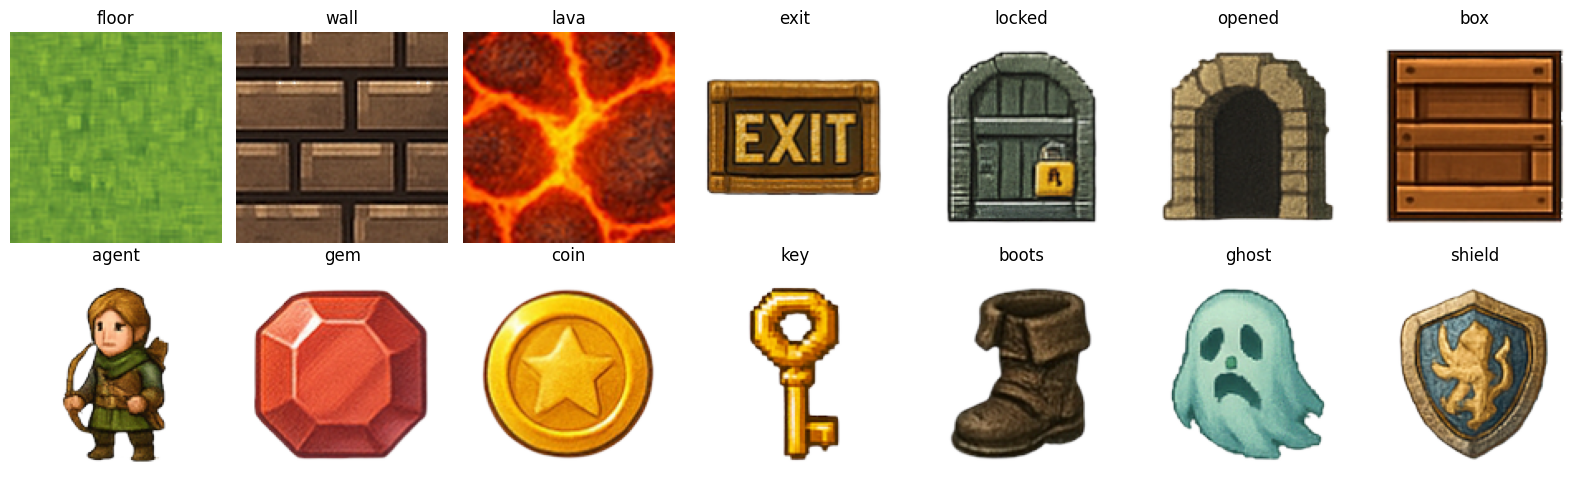

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import random

samples = []
for label in LABELS:
    image_path = random.choice(list((ASSETS / ASSET_NAME[label]).glob("*.png")))
    samples.append((label, Image.open(image_path).convert("RGBA")))

fig, axes = plt.subplots(2, 7, figsize=(16, 5))
for axis, (label, image) in zip(axes.flat, samples):
    axis.imshow(image)
    axis.set_title(label)
    axis.axis("off")

plt.tight_layout()

In [ ]:
import os
import random
import numpy as np
import torch

SEED = 2109

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", DEVICE)

Using: cuda


One last useful setup cell: create persistent output folders in Drive so a runtime reset never loses a model or diagnostic.

In [ ]:
RUNS = PROJECT / "runs"
CHECKPOINTS = PROJECT / "checkpoints"
EXPORTS = PROJECT / "exports"
DIAGNOSTICS = PROJECT / "diagnostics"

for directory in (RUNS, CHECKPOINTS, EXPORTS, DIAGNOSTICS):
    directory.mkdir(parents=True, exist_ok=True)

print("Persistent outputs:")
for directory in (RUNS, CHECKPOINTS, EXPORTS, DIAGNOSTICS):
    print("-", directory)

Persistent outputs:
- /content/drive/MyDrive/Colab Notebooks/runs
- /content/drive/MyDrive/Colab Notebooks/checkpoints
- /content/drive/MyDrive/Colab Notebooks/exports
- /content/drive/MyDrive/Colab Notebooks/diagnostics


Record the environment once:

In [ ]:
import sys
import torch
import torchvision
import numpy as np
import PIL

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Pillow:", PIL.__version__)
print("Device:", DEVICE)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
NumPy: 2.4.6
Pillow: 11.3.0
Device: cuda


Asset splitting.

In [ ]:
# Split source visual variants before generating any training examples.
# A source PNG may appear in exactly one split.

from collections import defaultdict

VAL_FRACTION = 0.20
SPLIT_RNG = random.Random(SEED)

asset_paths = {
    label: sorted((ASSETS / ASSET_NAME[label]).glob("*.png"))
    for label in LABELS
}

train_assets = {}
val_assets = {}

for label, paths in asset_paths.items():
    assert len(paths) >= 2, f"Need at least two assets for {label}"

    paths = paths.copy()
    SPLIT_RNG.shuffle(paths)

    val_count = max(1, round(len(paths) * VAL_FRACTION))
    val_assets[label] = paths[:val_count]
    train_assets[label] = paths[val_count:]

    assert not set(train_assets[label]) & set(val_assets[label])
    assert train_assets[label], f"No training assets left for {label}"

split_summary = {
    label: {
        "train": len(train_assets[label]),
        "val": len(val_assets[label]),
        "total": len(asset_paths[label]),
        "val_examples": [path.name for path in val_assets[label][:3]],
    }
    for label in LABELS
}
split_summary

{'floor': {'train': 20,
  'val': 5,
  'total': 25,
  'val_examples': ['floor_3.png', 'floor_1.png', 'floor_4.png']},
 'wall': {'train': 20,
  'val': 5,
  'total': 25,
  'val_examples': ['wall_10.png', 'wall_13.png', 'wall_21.png']},
 'lava': {'train': 20,
  'val': 5,
  'total': 25,
  'val_examples': ['lava_10.png', 'lava_7.png', 'lava_12.png']},
 'exit': {'train': 18,
  'val': 4,
  'total': 22,
  'val_examples': ['exit_19.png', 'exit_13.png', 'exit_16.png']},
 'locked': {'train': 18,
  'val': 4,
  'total': 22,
  'val_examples': ['locked_11.png', 'locked_16.png', 'locked_15.png']},
 'opened': {'train': 20,
  'val': 5,
  'total': 25,
  'val_examples': ['opened_16.png', 'opened_12.png', 'opened_7.png']},
 'box': {'train': 15,
  'val': 4,
  'total': 19,
  'val_examples': ['box_7.png', 'box_17.png', 'box_9.png']},
 'agent': {'train': 26,
  'val': 6,
  'total': 32,
  'val_examples': ['human_30.png', 'human_1.png', 'human_18.png']},
 'gem': {'train': 20,
  'val': 5,
  'total': 25,
  'val_exam

In [ ]:
from functools import lru_cache
from io import BytesIO
from PIL import ImageEnhance, ImageFilter
from torch.utils.data import Dataset

IMAGE_SIZE = 64
TRAIN_TILE_COUNT = 24_000
VAL_TILE_COUNT = 6_000

# Agent overlays are the only layered examples at this stage. These are the
# combinations relevant to image-mode state reconstruction.
PRIMARY_LABELS = (
    'floor', 'wall', 'lava', 'exit', 'locked', 'opened', 'box',
    'gem', 'coin', 'key', 'boots', 'ghost', 'shield',
)
AGENT_BASE_LABELS = ('exit', 'gem', 'coin', 'key', 'boots', 'ghost', 'shield')

@lru_cache(maxsize=None)
def load_rgba(path_string):
    with Image.open(path_string) as image:
        return image.convert('RGBA').copy()

def choose_asset(asset_dict, label, rng):
    return load_rgba(str(rng.choice(asset_dict[label]))).copy()

def apply_visual_augmentation(image, rng):
    # A small resize-and-crop models renderer/capture alignment variation.
    scaled = image.resize((68, 68), Image.Resampling.BICUBIC)
    left, top = rng.randrange(5), rng.randrange(5)
    image = scaled.crop((left, top, left + IMAGE_SIZE, top + IMAGE_SIZE))

    rgb, alpha = image.convert('RGB'), image.getchannel('A')
    rgb = ImageEnhance.Brightness(rgb).enhance(rng.uniform(0.85, 1.15))
    rgb = ImageEnhance.Contrast(rgb).enhance(rng.uniform(0.85, 1.15))
    rgb = ImageEnhance.Color(rgb).enhance(rng.uniform(0.85, 1.15))

    if rng.random() < 0.30:
        rgb = rgb.filter(ImageFilter.GaussianBlur(rng.uniform(0.15, 0.65)))

    # JPEG is applied to RGB only; alpha remains the original semantic mask.
    if rng.random() < 0.30:
        buffer = BytesIO()
        rgb.save(buffer, format='JPEG', quality=rng.randint(72, 95))
        buffer.seek(0)
        with Image.open(buffer) as compressed:
            rgb = compressed.convert('RGB').copy()

    pixels = np.asarray(rgb, dtype=np.int16)
    noise = np.asarray(
        [rng.gauss(0.0, 2.0) for _ in range(pixels.size)], dtype=np.float32
    ).reshape(pixels.shape)
    pixels = np.clip(pixels + noise, 0, 255).astype(np.uint8)
    return Image.merge('RGBA', (*Image.fromarray(pixels).split(), alpha))

class SyntheticTileDataset(Dataset):
    def __init__(self, asset_dict, count, *, augment, seed):
        self.asset_dict = asset_dict
        self.count = count
        self.augment = augment
        self.seed = seed

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return self.count

    def __getitem__(self, index):
        epoch = getattr(self, 'epoch', 0)
        rng = random.Random(self.seed + index + epoch * self.count)
        primary = rng.choice(PRIMARY_LABELS)
        layers = [] if primary == 'floor' else [primary]

        # About one third of eligible examples contain an agent overlay,
        # including an agent standing on an otherwise bare floor.
        if primary == 'floor' and rng.random() < 0.35:
            layers.append('agent')
        elif primary in AGENT_BASE_LABELS and rng.random() < 0.35:
            layers.append('agent')

        background = choose_asset(self.asset_dict, 'floor', rng)
        image = background.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
        target = torch.zeros(len(LABELS), dtype=torch.float32)

        if not layers:
            target[LABEL_TO_INDEX['floor']] = 1.0
        else:
            for label in layers:
                target[LABEL_TO_INDEX[label]] = 1.0
                overlay = choose_asset(self.asset_dict, label, rng)
                overlay = overlay.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
                image = Image.alpha_composite(image, overlay)

        if self.augment:
            image = apply_visual_augmentation(image, rng)

        array = np.ascontiguousarray(np.asarray(image, dtype=np.float32) / 255.0)
        tensor = torch.from_numpy(array).permute(2, 0, 1)
        return tensor, target

train_dataset = SyntheticTileDataset(
    train_assets, TRAIN_TILE_COUNT, augment=True, seed=SEED
)
val_dataset = SyntheticTileDataset(
    val_assets, VAL_TILE_COUNT, augment=False, seed=SEED + 1_000_000
)

print(f'Train tiles: {len(train_dataset):,}; validation tiles: {len(val_dataset):,}')
print('Tensor shape:', tuple(train_dataset[0][0].shape), 'labels:', len(LABELS))

Train tiles: 24,000; validation tiles: 6,000
Tensor shape: (4, 64, 64) labels: 14


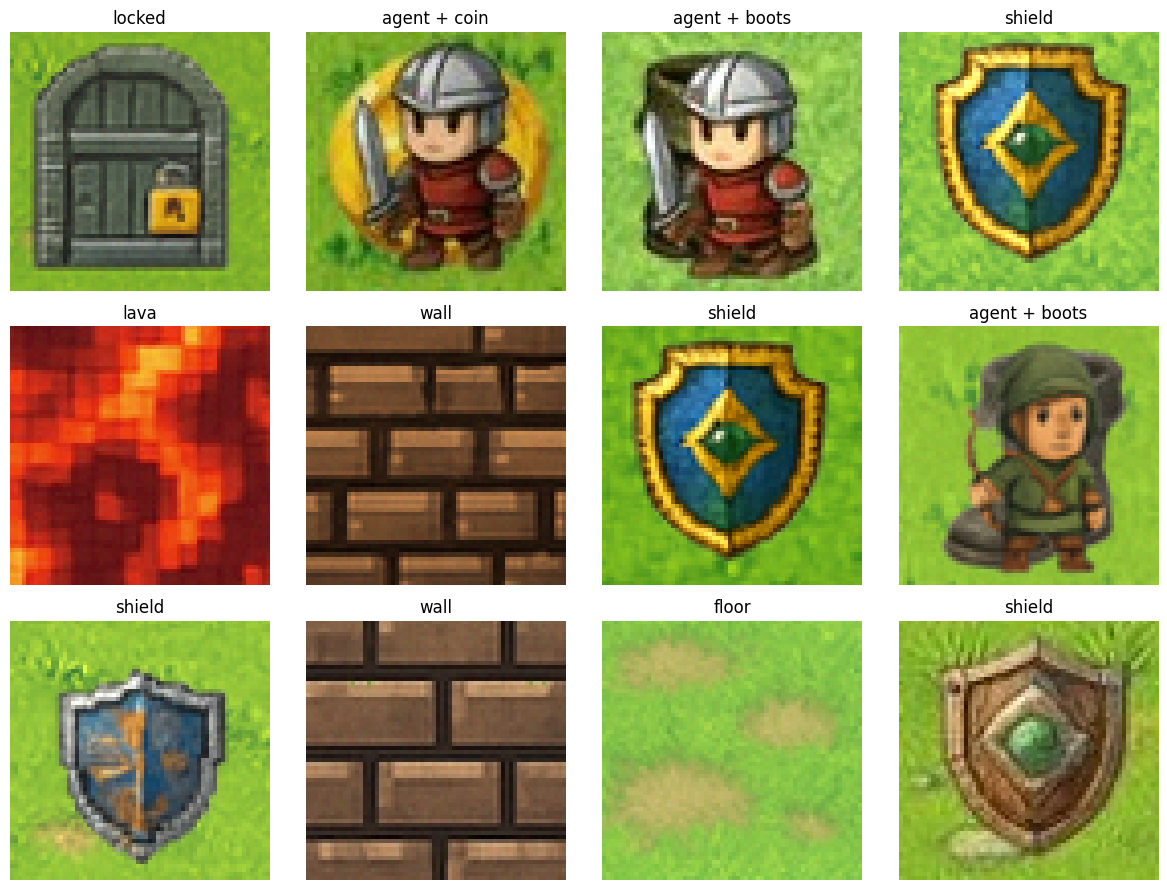

In [ ]:
def show_samples(dataset, count=12):
    indices = random.sample(range(len(dataset)), count)
    figure, axes = plt.subplots(3, 4, figsize=(12, 9))
    for axis, index in zip(axes.flat, indices):
        image, target = dataset[index]
        labels = [LABELS[i] for i, value in enumerate(target) if value.item() > 0.5]
        axis.imshow(image.permute(1, 2, 0).numpy())
        axis.set_title(' + '.join(labels))
        axis.axis('off')
    plt.tight_layout()

show_samples(train_dataset)

In [ ]:
from torch import nn
from torch.utils.data import DataLoader

BATCH_SIZE = 128
NUM_WORKERS = 2 if DEVICE.type == 'cuda' else 0

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'),
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'),
)

class TileMultiLabelCNN(nn.Module):
    def __init__(self, num_labels=len(LABELS)):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 96, kernel_size=3, padding=1),
            nn.BatchNorm2d(96), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(96, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Linear(128, num_labels)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

model = TileMultiLabelCNN().to(DEVICE)
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f'Model parameters: {parameter_count:,}')
print('Example logits:', tuple(model(torch.zeros(2, 4, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE)).shape))

Model parameters: 188,238
Example logits: (2, 14)


In [ ]:
EPOCHS = 15
LEARNING_RATE = 1e-3

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
BEST_CHECKPOINT = CHECKPOINTS / 'tile_multilabel_cnn_best.pt'

def evaluate(loader):
    model.eval()
    total_loss = 0.0
    sample_count = 0
    true_positive = torch.zeros(len(LABELS), dtype=torch.long)
    false_positive = torch.zeros(len(LABELS), dtype=torch.long)
    false_negative = torch.zeros(len(LABELS), dtype=torch.long)

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(images)
            total_loss += criterion(logits, targets).item() * images.size(0)
            sample_count += images.size(0)
            predictions = torch.sigmoid(logits) >= 0.5
            expected = targets.bool()
            true_positive += (predictions & expected).sum(0).cpu()
            false_positive += (predictions & ~expected).sum(0).cpu()
            false_negative += (~predictions & expected).sum(0).cpu()

    precision = true_positive.float() / (true_positive + false_positive).clamp_min(1)
    recall = true_positive.float() / (true_positive + false_negative).clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-8)
    return total_loss / sample_count, precision, recall, f1

history = []
best_macro_f1 = -1.0

for epoch in range(EPOCHS):
    train_dataset.set_epoch(epoch)
    model.train()
    train_loss_total = 0.0
    train_samples = 0

    for images, targets in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), targets)
        loss.backward()
        optimizer.step()
        train_loss_total += loss.item() * images.size(0)
        train_samples += images.size(0)

    scheduler.step()
    val_loss, precision, recall, f1 = evaluate(val_loader)
    macro_f1 = f1.mean().item()
    record = {
        'epoch': epoch + 1,
        'train_loss': train_loss_total / train_samples,
        'val_loss': val_loss,
        'macro_f1': macro_f1,
    }
    history.append(record)
    print(
        f"epoch {epoch + 1:02d}/{EPOCHS}: train={record['train_loss']:.4f} "
        f"val={val_loss:.4f} macro-F1={macro_f1:.4f}"
    )

    if macro_f1 > best_macro_f1:
        best_macro_f1 = macro_f1
        torch.save({
            'state_dict': model.state_dict(),
            'labels': LABELS,
            'image_size': IMAGE_SIZE,
            'epoch': epoch + 1,
            'macro_f1': macro_f1,
        }, BEST_CHECKPOINT)

# Report metrics for the checkpoint selected by held-out macro-F1, not merely
# the final epoch.
best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE)
model.load_state_dict(best_checkpoint['state_dict'])
_, precision, recall, f1 = evaluate(val_loader)

metrics = {
    label: {
        'precision': round(precision[index].item(), 4),
        'recall': round(recall[index].item(), 4),
        'f1': round(f1[index].item(), 4),
    }
    for index, label in enumerate(LABELS)
}
print(f'Best validation macro-F1: {best_macro_f1:.4f}')
print(f'Checkpoint: {BEST_CHECKPOINT}')
metrics

NameError: name 'nn' is not defined

In [ ]:
print("Checkpoint:", BEST_CHECKPOINT)
print("Exists:", BEST_CHECKPOINT.exists())
print("Size (MB):", round(BEST_CHECKPOINT.stat().st_size / 1024**2, 2))

checkpoint = torch.load(BEST_CHECKPOINT, map_location="cpu")
print("Best epoch:", checkpoint["epoch"])
print("Held-out macro-F1:", checkpoint["macro_f1"])
print("Labels:", checkpoint["labels"])

Checkpoint: /content/drive/MyDrive/Colab Notebooks/checkpoints/tile_multilabel_cnn_best.pt
Exists: True
Size (MB): 0.73
Best epoch: 15
Held-out macro-F1: 0.9993862509727478
Labels: ('floor', 'wall', 'lava', 'exit', 'locked', 'opened', 'box', 'agent', 'gem', 'coin', 'key', 'boots', 'ghost', 'shield')


In [ ]:
# Re-load the best model in case a later notebook cell changed `model`.
best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE)
model.load_state_dict(best_checkpoint['state_dict'])
model.eval()

failure_records = []
false_positive_counts = Counter()
false_negative_counts = Counter()
sample_offset = 0

with torch.no_grad():
    for images, targets in val_loader:
        probabilities = torch.sigmoid(model(images.to(DEVICE))).cpu()
        expected = targets.bool()
        predicted = probabilities >= 0.5
        error_rows = (predicted != expected).any(dim=1).nonzero(as_tuple=True)[0]

        for row in error_rows.tolist():
            false_positive = predicted[row] & ~expected[row]
            false_negative = ~predicted[row] & expected[row]
            fp_labels = [LABELS[index] for index in false_positive.nonzero().flatten().tolist()]
            fn_labels = [LABELS[index] for index in false_negative.nonzero().flatten().tolist()]
            false_positive_counts.update(fp_labels)
            false_negative_counts.update(fn_labels)

            # Confidence is high when the wrong side of 0.5 was chosen decisively.
            wrong_confidences = torch.where(
                false_positive, probabilities[row], 1.0 - probabilities[row]
            )
            wrong_confidence = wrong_confidences[(false_positive | false_negative)].max().item()
            failure_records.append({
                'index': sample_offset + row,
                'image': images[row].cpu(),
                'expected': [LABELS[index] for index in expected[row].nonzero().flatten().tolist()],
                'predicted': [LABELS[index] for index in predicted[row].nonzero().flatten().tolist()],
                'false_positive': fp_labels,
                'false_negative': fn_labels,
                'confidence': wrong_confidence,
            })

        sample_offset += len(images)

failure_summary = {
    'validation_tiles': sample_offset,
    'tiles_with_any_error': len(failure_records),
    'false_positives': dict(false_positive_counts),
    'false_negatives': dict(false_negative_counts),
}
failure_summary

NameError: name 'BEST_CHECKPOINT' is not defined

#3484  confidence=0.842

expected: agent, gem

predicted: agent, ghost

FP: ['ghost']  FN: ['gem']
#2191  confidence=0.797

expected: agent, gem

predicted: agent, gem, ghost

FP: ['ghost']  FN: -
#4435  confidence=0.714

expected: agent, gem

predicted: agent, gem, ghost

FP: ['ghost']  FN: -
#3564  confidence=0.673

expected: agent, gem

predicted: agent, gem, ghost

FP: ['ghost']  FN: -
#274  confidence=0.501

expected: agent, gem

predicted: agent, gem, ghost

FP: ['ghost']  FN: -
#3480  confidence=0.501

expected: agent, gem

predicted: agent, gem, ghost

FP: ['ghost']  FN: -
#4723  confidence=0.501

expected: agent, gem

predicted: agent, gem, ghost

FP: ['ghost']  FN: -


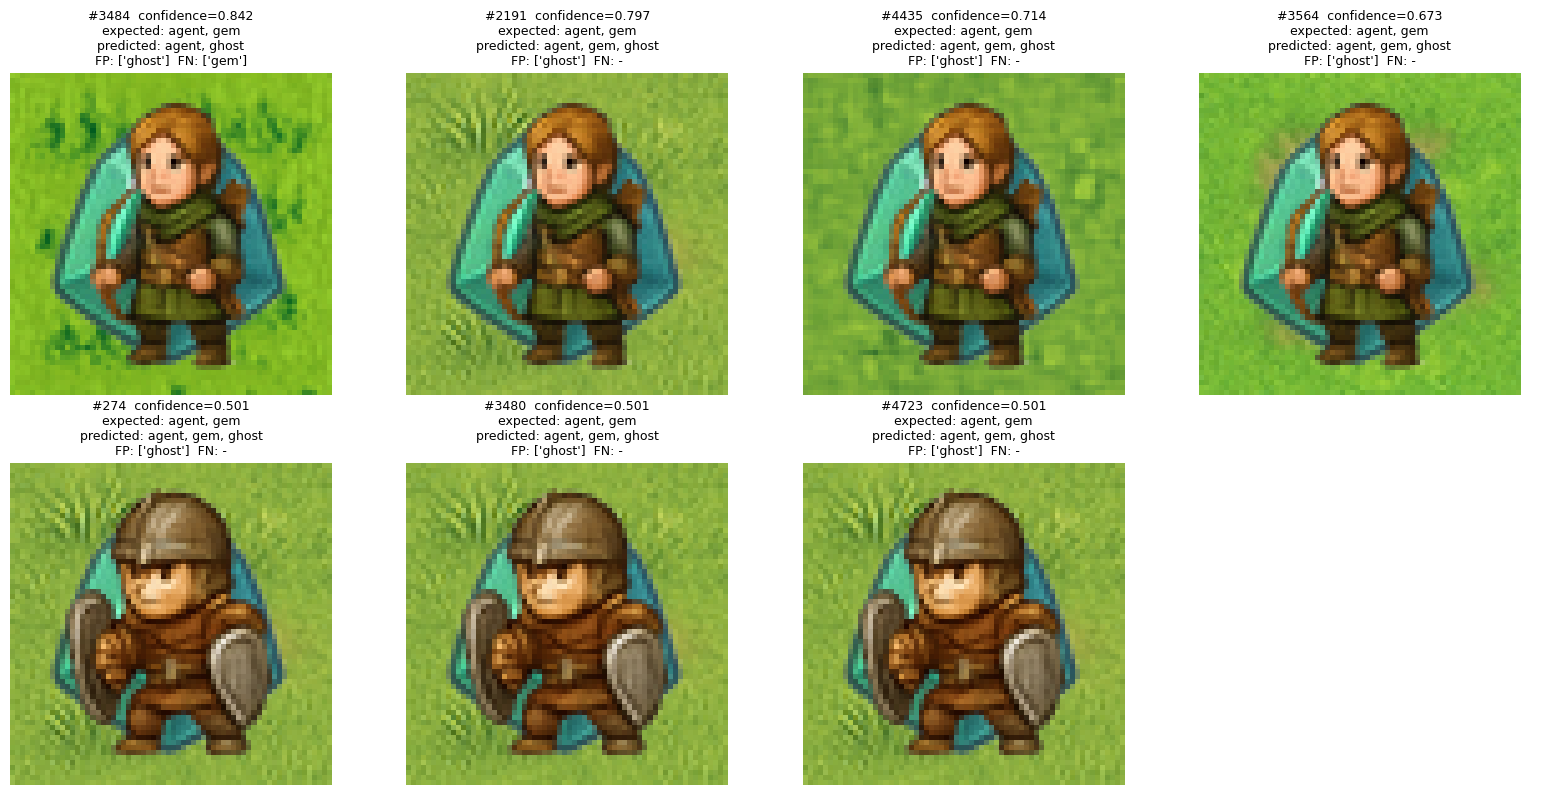

In [ ]:
def show_failures(records, count=16):
    if not records:
        print('No held-out validation failures at the 0.5 threshold.')
        return

    records = sorted(records, key=lambda record: record['confidence'], reverse=True)[:count]
    columns = 4
    rows = (len(records) + columns - 1) // columns
    figure, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * rows))
    for axis, record in zip(np.ravel(axes), records):
        axis.imshow(record['image'].permute(1, 2, 0).numpy())
        axis.set_title(
            f"#{record['index']}  confidence={record['confidence']:.3f}\n"
            f"expected: {', '.join(record['expected'])}\n"
            f"predicted: {', '.join(record['predicted'])}\n"
            f"FP: {record['false_positive'] or '-'}  FN: {record['false_negative'] or '-'}",
            fontsize=9,
        )
        print(f"#{record['index']}  confidence={record['confidence']:.3f}\n")
        print(f"expected: {', '.join(record['expected'])}\n")
        print(f"predicted: {', '.join(record['predicted'])}\n")
        print(f"FP: {record['false_positive'] or '-'}  FN: {record['false_negative'] or '-'}")
        axis.axis('off')
    for axis in np.ravel(axes)[len(records):]:
        axis.axis('off')
    plt.tight_layout()

show_failures(failure_records)

Addressing the gem-ghost confusion.

In [ ]:
# Collect the complete held-out probability matrix once.
model.eval()
validation_probabilities = []
validation_targets = []
with torch.no_grad():
    for images, targets in val_loader:
        validation_probabilities.append(torch.sigmoid(model(images.to(DEVICE))).cpu())
        validation_targets.append(targets.cpu())

validation_probabilities = torch.cat(validation_probabilities)
validation_targets = torch.cat(validation_targets).bool()
assert validation_probabilities.shape == validation_targets.shape

def binary_scores(probabilities, targets, threshold):
    predictions = probabilities >= threshold
    tp = (predictions & targets).sum().item()
    fp = (predictions & ~targets).sum().item()
    fn = (~predictions & targets).sum().item()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-8)
    return precision, recall, f1, fp, fn

# Fine enough to inspect calibration without tuning to a single probability.
THRESHOLD_GRID = torch.arange(0.05, 0.951, 0.005)
calibrated_thresholds = {}
threshold_report = {}

for index, label in enumerate(LABELS):
    probabilities = validation_probabilities[:, index]
    targets = validation_targets[:, index]
    candidates = []
    for threshold in THRESHOLD_GRID.tolist():
        precision, recall, f1, fp, fn = binary_scores(probabilities, targets, threshold)
        candidates.append((f1, recall, precision, threshold, fp, fn))

    # Prefer F1; break ties toward recall so mandatory entities are not missed.
    best_f1, best_recall, best_precision, best_threshold, best_fp, best_fn = max(
        candidates, key=lambda item: (item[0], item[1], item[2], item[3])
    )
    default_precision, default_recall, default_f1, default_fp, default_fn = binary_scores(
        probabilities, targets, 0.5
    )
    calibrated_thresholds[label] = round(best_threshold, 3)
    threshold_report[label] = {
        'threshold': round(best_threshold, 3),
        'default_f1': round(default_f1, 4),
        'calibrated_f1': round(best_f1, 4),
        'default_fp': default_fp,
        'default_fn': default_fn,
        'calibrated_fp': best_fp,
        'calibrated_fn': best_fn,
    }

print('Decoder thresholds:', calibrated_thresholds)
threshold_report

Decoder thresholds: {'floor': 0.95, 'wall': 0.95, 'lava': 0.95, 'exit': 0.95, 'locked': 0.84, 'opened': 0.935, 'box': 0.95, 'agent': 0.88, 'gem': 0.4, 'coin': 0.95, 'key': 0.555, 'boots': 0.85, 'ghost': 0.95, 'shield': 0.545}


{'floor': {'threshold': 0.95,
  'default_f1': 1.0,
  'calibrated_f1': 1.0,
  'default_fp': 0,
  'default_fn': 0,
  'calibrated_fp': 0,
  'calibrated_fn': 0},
 'wall': {'threshold': 0.95,
  'default_f1': 1.0,
  'calibrated_f1': 1.0,
  'default_fp': 0,
  'default_fn': 0,
  'calibrated_fp': 0,
  'calibrated_fn': 0},
 'lava': {'threshold': 0.95,
  'default_f1': 1.0,
  'calibrated_f1': 1.0,
  'default_fp': 0,
  'default_fn': 0,
  'calibrated_fp': 0,
  'calibrated_fn': 0},
 'exit': {'threshold': 0.95,
  'default_f1': 1.0,
  'calibrated_f1': 1.0,
  'default_fp': 0,
  'default_fn': 0,
  'calibrated_fp': 0,
  'calibrated_fn': 0},
 'locked': {'threshold': 0.84,
  'default_f1': 1.0,
  'calibrated_f1': 1.0,
  'default_fp': 0,
  'default_fn': 0,
  'calibrated_fp': 0,
  'calibrated_fn': 0},
 'opened': {'threshold': 0.935,
  'default_f1': 1.0,
  'calibrated_f1': 1.0,
  'default_fp': 0,
  'default_fn': 0,
  'calibrated_fp': 0,
  'calibrated_fn': 0},
 'box': {'threshold': 0.95,
  'default_f1': 1.0,
  '

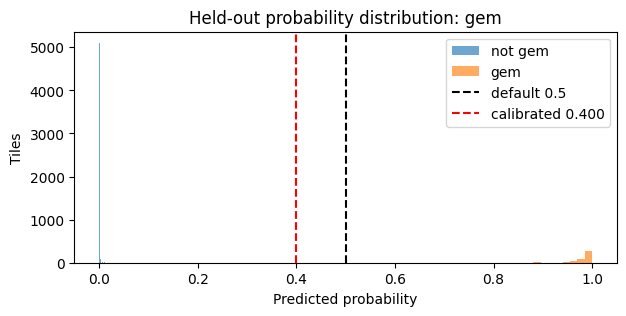

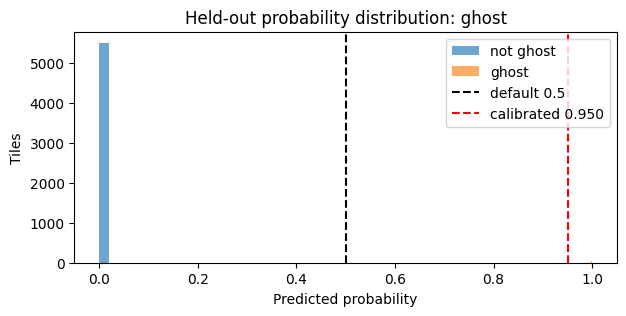

In [ ]:
# Focus on the two labels implicated by the error inspection.
for label in ('gem', 'ghost'):
    index = LABEL_TO_INDEX[label]
    probabilities = validation_probabilities[:, index].numpy()
    targets = validation_targets[:, index].numpy()
    plt.figure(figsize=(7, 3))
    plt.hist(probabilities[~targets], bins=40, alpha=0.65, label=f'not {label}')
    plt.hist(probabilities[targets], bins=40, alpha=0.65, label=label)
    plt.axvline(0.5, color='black', linestyle='--', label='default 0.5')
    plt.axvline(calibrated_thresholds[label], color='red', linestyle='--',
                label=f"calibrated {calibrated_thresholds[label]:.3f}")
    plt.title(f'Held-out probability distribution: {label}')
    plt.xlabel('Predicted probability')
    plt.ylabel('Tiles')
    plt.legend()
    plt.show()

In [ ]:
# Conservative thresholds to embed in the submission-side image decoder.
DECODER_THRESHOLDS = {label: 0.50 for label in LABELS}
DECODER_THRESHOLDS.update({
    'gem': 0.40,    # recovers the only held-out gem false negative
    'ghost': 0.90,  # clears the worst observed ghost false positive (0.842)
})

threshold_tensor = torch.tensor(
    [DECODER_THRESHOLDS[label] for label in LABELS], dtype=validation_probabilities.dtype
)
calibrated_predictions = validation_probabilities >= threshold_tensor
calibrated_errors = (calibrated_predictions != validation_targets).any(dim=1)
print('Locked thresholds:', DECODER_THRESHOLDS)
print(f'Held-out tiles with any error: {calibrated_errors.sum().item()} / {len(calibrated_errors)}')
assert not calibrated_errors.any(), 'Inspect the remaining calibration errors before export.'

NameError: name 'validation_probabilities' is not defined

In [ ]:
import importlib.util
import sys

UTILS_PATH = PROJECT / 'utils.py'
if not UTILS_PATH.exists():
    raise FileNotFoundError(
        f'Copy the course utils.py to {UTILS_PATH} before exporting.'
    )

spec = importlib.util.spec_from_file_location('course_utils', UTILS_PATH)
assert spec is not None and spec.loader is not None
course_utils = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = course_utils  # required for decorators in utils.py
spec.loader.exec_module(course_utils)

# The best checkpoint—not merely the final in-memory epoch—is the export source.
best_checkpoint = torch.load(BEST_CHECKPOINT, map_location='cpu')
model = TileMultiLabelCNN()
model.load_state_dict(best_checkpoint['state_dict'])
model.eval()
example_inputs = torch.zeros(1, 4, IMAGE_SIZE, IMAGE_SIZE, dtype=torch.float32)

loader_snippet = course_utils.generate_torch_loader_snippet(
    model,
    example_inputs=example_inputs,
    prefer='auto',
    compression='zlib',
)

LOADER_SNIPPET_PATH = EXPORTS / 'tile_model_loader.py'
LOADER_SNIPPET_PATH.write_text(loader_snippet, encoding='utf-8')
print(f'Inline loader saved to: {LOADER_SNIPPET_PATH}')
print(f'Loader source size: {LOADER_SNIPPET_PATH.stat().st_size / 1024:.1f} KiB')
print('Paste the get_model(...) function from this file into the submission agent.')

NameError: name 'BEST_CHECKPOINT' is not defined

In [ ]:
# Test the saved artifact itself; no large source needs to be pasted into this notebook.
isolated_namespace = {'__name__': 'embedded_tile_model'}
saved_loader_source = LOADER_SNIPPET_PATH.read_text(encoding='utf-8')
exec(compile(saved_loader_source, str(LOADER_SNIPPET_PATH), 'exec'), isolated_namespace)
embedded_model = isolated_namespace['get_model'](device='cpu')

verification_input = torch.rand(3, 4, IMAGE_SIZE, IMAGE_SIZE)
with torch.no_grad():
    reference_logits = model(verification_input)
    embedded_logits = embedded_model(verification_input)

torch.testing.assert_close(reference_logits, embedded_logits, rtol=1e-5, atol=1e-6)
print('Export verification passed: embedded TorchScript logits match checkpoint logits.')
print(type(embedded_model))

NameError: name 'LOADER_SNIPPET_PATH' is not defined

Export TorchScript without dealing with the large binary.

In [ ]:
# Test the saved artifact itself; no large source needs to be pasted into this notebook.
# Define the path here as well, so this cell does not depend on the preceding
# inline-export cell having run in the current Colab kernel.
LOADER_SNIPPET_PATH = EXPORTS / 'tile_model_loader.py'
if not LOADER_SNIPPET_PATH.exists():
    raise FileNotFoundError(
        f'Inline loader not found: {LOADER_SNIPPET_PATH}. '
        'Run the Inline TorchScript export cell first; no model retraining is needed.'
    )

isolated_namespace = {'__name__': 'embedded_tile_model'}
saved_loader_source = LOADER_SNIPPET_PATH.read_text(encoding='utf-8')
exec(compile(saved_loader_source, str(LOADER_SNIPPET_PATH), 'exec'), isolated_namespace)
embedded_model = isolated_namespace['get_model'](device='cpu')

verification_input = torch.rand(3, 4, IMAGE_SIZE, IMAGE_SIZE)
with torch.no_grad():
    embedded_logits = embedded_model(verification_input)

assert embedded_logits.shape == (3, 14), embedded_logits.shape
assert torch.isfinite(embedded_logits).all(), 'Embedded model returned non-finite logits.'
print('Inline-loader smoke test passed: embedded TorchScript loads and produces 14 finite logits per tile.')
print(type(embedded_model))

RuntimeError: Run the Model and data loaders cell once to define TileMultiLabelCNN. It defines the architecture only; retraining is not required.

In [ ]:
# Export a standalone TorchScript file for local use.
# This assumes TileMultiLabelCNN, IMAGE_SIZE, BEST_CHECKPOINT, and EXPORTS
# have been defined by the earlier notebook cells.
if 'TileMultiLabelCNN' not in globals():
    raise RuntimeError(
        'Run the Model and data loaders cell once to define TileMultiLabelCNN. '
        'It defines the architecture only; retraining is not required.'
    )
if not BEST_CHECKPOINT.exists():
    raise FileNotFoundError(f'Best checkpoint not found: {BEST_CHECKPOINT}')

EXPORTS.mkdir(parents=True, exist_ok=True)
TORCHSCRIPT_PATH = EXPORTS / 'tile_multilabel_cnn_best.torchscript.pt'
print(f'Exporting checkpoint: {BEST_CHECKPOINT.resolve()}')
print(f'TorchScript destination: {TORCHSCRIPT_PATH.resolve()}')

best_checkpoint = torch.load(BEST_CHECKPOINT, map_location='cpu')
model = TileMultiLabelCNN()
model.load_state_dict(best_checkpoint['state_dict'])
model.eval()

example_inputs = torch.zeros(1, 4, IMAGE_SIZE, IMAGE_SIZE, dtype=torch.float32)
# tracing is appropriate here: the CNN has a fixed tensor-only forward path.
scripted_model = torch.jit.trace(model, example_inputs, strict=True)
torch.jit.save(scripted_model, TORCHSCRIPT_PATH)

# Smoke-test the on-disk artifact. The trace itself has already checked
# equivalence with the reconstructed checkpoint model; do not require a
# separate reference-model binding after the file is saved.
reloaded_model = torch.jit.load(TORCHSCRIPT_PATH, map_location='cpu').eval()
verification_input = torch.rand(3, 4, IMAGE_SIZE, IMAGE_SIZE)
with torch.no_grad():
    torchscript_logits = reloaded_model(verification_input)
assert torchscript_logits.shape == (3, 14), torchscript_logits.shape
assert torch.isfinite(torchscript_logits).all(), 'TorchScript model returned non-finite logits.'
print(f'TorchScript file saved to: {TORCHSCRIPT_PATH}')
print(f'TorchScript size: {TORCHSCRIPT_PATH.stat().st_size / 1024:.1f} KiB')
print('File-based TorchScript verification passed.')

Exporting checkpoint: /content/drive/MyDrive/Colab Notebooks/checkpoints/tile_multilabel_cnn_best.pt
TorchScript destination: /content/drive/MyDrive/Colab Notebooks/exports/tile_multilabel_cnn_best.torchscript.pt
TorchScript file saved to: /content/drive/MyDrive/Colab Notebooks/exports/tile_multilabel_cnn_best.torchscript.pt
TorchScript size: 781.9 KiB
File-based TorchScript verification passed.
